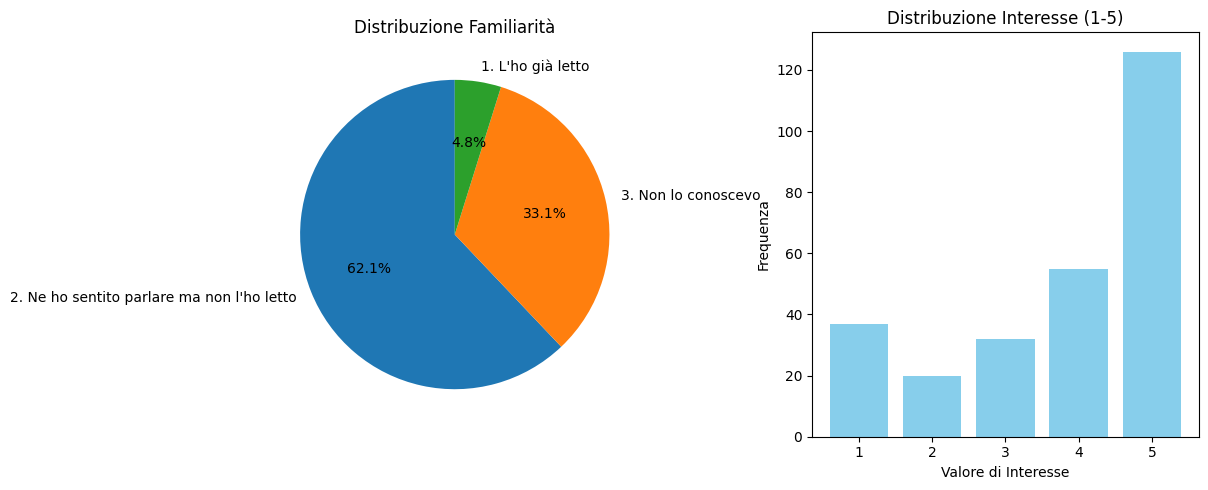

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Carica il file Excel
file_path = "valutazioni.xlsx"
df = pd.read_excel(file_path, sheet_name='Risposte del modulo 1')

# Estrai tutte le colonne di Familiarità e Interesse
familiarita_cols = [col for col in df.columns if 'Familiarità' in col]
interesse_cols = [col for col in df.columns if 'Interesse' in col]

# Serie unica per Familiarità
familiarita_values = pd.concat([df[col] for col in familiarita_cols], ignore_index=True).dropna()

# Serie unica per Interesse (convertendo in numerico)
interesse_values = pd.concat([df[col] for col in interesse_cols], ignore_index=True)
interesse_values = pd.to_numeric(interesse_values, errors='coerce').dropna()

# Conta le frequenze
familiarita_counts = familiarita_values.value_counts()
interesse_counts = interesse_values.value_counts().sort_index()

# Mantieni solo valori 1-5 per interesse
interesse_counts = interesse_counts.loc[interesse_counts.index.isin([1, 2, 3, 4, 5])]

# Grafico a torta per Familiarità
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.pie(familiarita_counts, labels=familiarita_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribuzione Familiarità')

# Grafico a barre per Interesse
plt.subplot(1, 2, 2)
plt.bar(interesse_counts.index.astype(int), interesse_counts.values, color='skyblue')
plt.xticks([1, 2, 3, 4, 5])
plt.title('Distribuzione Interesse (1-5)')
plt.xlabel('Valore di Interesse')
plt.ylabel('Frequenza')

plt.tight_layout()
plt.show()


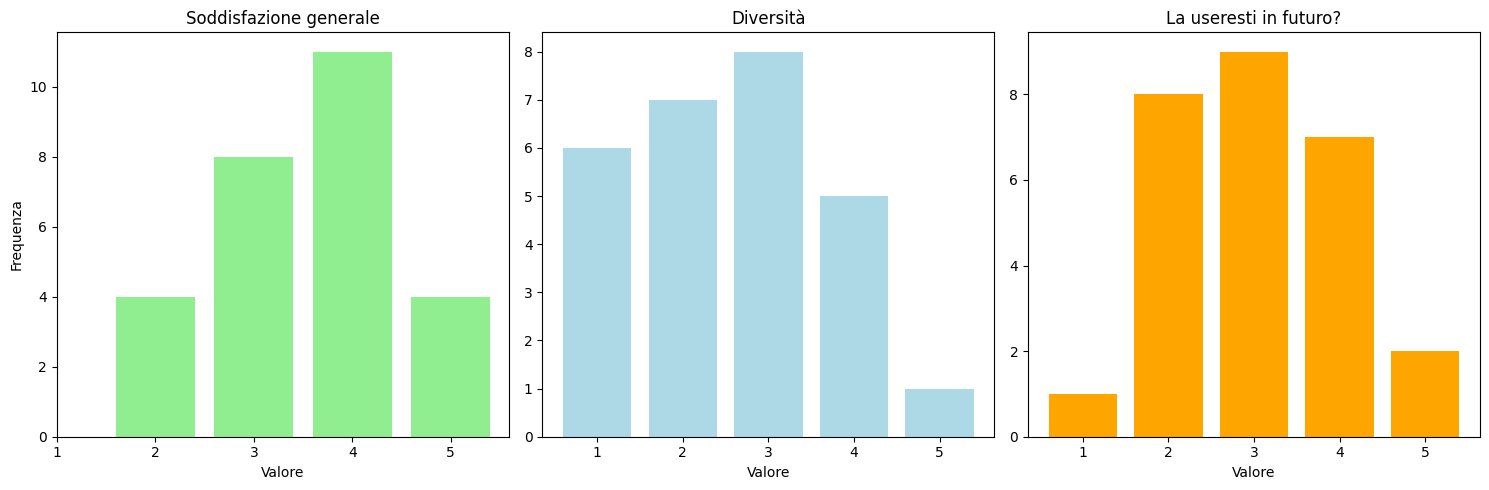

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Carica il file Excel
file_path = "valutazioni.xlsx"
df = pd.read_excel(file_path, sheet_name='Risposte del modulo 1')

# Colonne per le nuove metriche
soddisf_cols = [col for col in df.columns if 'Soddisfazione generale' in col]
divers_cols = [col for col in df.columns if 'Diversità' in col]
ritorneresti_cols = [col for col in df.columns if 'Utilizzeresti la piattaforma per altre raccomandazioni?' in col]

# Funzione per calcolare le frequenze da 1 a 5
def get_counts(cols):
    values = pd.concat([df[col] for col in cols], ignore_index=True)
    values = pd.to_numeric(values, errors='coerce').dropna()
    counts = values.value_counts().sort_index()
    return counts.loc[counts.index.isin([1, 2, 3, 4, 5])]

# Calcola le frequenze per le tre metriche
soddisf_counts = get_counts(soddisf_cols)
divers_counts = get_counts(divers_cols)
ritorneresti_counts = get_counts(ritorneresti_cols)

# Crea i grafici
plt.figure(figsize=(15, 5))

# Soddisfazione
plt.subplot(1, 3, 1)
plt.bar(soddisf_counts.index.astype(int), soddisf_counts.values, color='lightgreen')
plt.xticks([1, 2, 3, 4, 5])
plt.title('Soddisfazione generale')
plt.xlabel('Valore')
plt.ylabel('Frequenza')

# Diversità
plt.subplot(1, 3, 2)
plt.bar(divers_counts.index.astype(int), divers_counts.values, color='lightblue')
plt.xticks([1, 2, 3, 4, 5])
plt.title('Diversità')
plt.xlabel('Valore')

# Ritorneresti
plt.subplot(1, 3, 3)
plt.bar(ritorneresti_counts.index.astype(int), ritorneresti_counts.values, color='orange')
plt.xticks([1, 2, 3, 4, 5])
plt.title('La useresti in futuro?')
plt.xlabel('Valore')

plt.tight_layout()
plt.show()
